# Regressão linear do zero — OLS, GD e SGD com NumPy e scikit-learn

Vamos prever `median_house_value` usando o arquivo **housing.csv desta pasta**. Primeiro implementaremos mínimos quadrados com NumPy: solução direta (**OLS**), descida do gradiente em lote (**GD**) e descida do gradiente estocástica (**SGD**). Depois treinaremos modelos do scikit-learn com os mesmos dados e compararemos as previsões.

**Continuidade da aula:** o [notebook de regressão logística](../Regressão%20Logística/regressao-logistica-livecoding.ipynb) já explicou vetores, matrizes, intercepto, coluna de 1s, produto `@`, separação treino/teste, padronização e a ideia geral de descida do gradiente. Reutilizaremos esses conceitos sem repetir suas deduções. Aqui detalhamos o que muda: saída contínua, tratamento de ausentes e categorias, erro quadrático, equações normais, solução numérica de OLS, atualizações de GD e SGD, métricas e diagnóstico dos resíduos.

**Execução:** use as dependências do `requirements.txt` da raiz e execute as células em ordem. O CSV pode ser encontrado tanto executando a partir desta pasta quanto da raiz do projeto. Os resultados e gráficos ficam salvos após a execução completa.

**Roteiro:** dados → preparação em NumPy → modelo e MSE → OLS → GD → SGD → curvas de MSE → métricas → scikit-learn → interpretação. Não ajustaremos configurações a partir do teste.


## 1. Importações e leitura do dataset

Mantemos pandas para leitura e tabelas, NumPy para preparar os dados e treinar os três procedimentos e Matplotlib para os gráficos. Os estimadores do scikit-learn só serão usados depois das implementações manuais.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

candidatos = [Path("housing.csv"), Path("Regressão LInear") / "housing.csv"]
caminho = next((p for p in candidatos if p.is_file()), None)
if caminho is None:
    raise FileNotFoundError("Execute na raiz do projeto ou na pasta que contém housing.csv.")
dados = pd.read_csv(caminho)
print("Dimensões:", dados.shape)
dados.head()


Dimensões: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


**Leitura do código:** `Path` representa caminhos; `next` seleciona o primeiro arquivo existente. Se nenhum for encontrado, a exceção informa onde executar. A leitura não baixa nem substitui o dataset local. As três funções de métricas serão usadas para conferir nossas contas; `LinearRegression` e `SGDRegressor` farão os ajustes de referência.

### O que representa cada linha?

Uma linha descreve um **grupo de quarteirões do censo**, e a resposta é o valor mediano das moradias desse grupo, em dólares da base histórica. Não estamos prevendo o preço individual de cada casa. O arquivo tem a estrutura da versão modificada de California Housing usada em *Hands-On Machine Learning*, baseada no censo de 1990 ([descrição da versão](https://github.com/ageron/handson-ml/blob/master/datasets/housing/README.md)). O CSV local não contém metadados que comprovem sua cadeia de origem.

| Coluna | Papel e significado |
|---|---|
| `longitude`, `latitude` | Localização do grupo |
| `housing_median_age` | Idade mediana das moradias |
| `total_rooms`, `total_bedrooms` | Totais de cômodos e dormitórios do grupo |
| `population`, `households` | População e número de domicílios |
| `median_income` | Indicador de renda mediana da base |
| `ocean_proximity` | Categoria de proximidade do oceano |
| `median_house_value` | **Alvo contínuo**, valor mediano das moradias |

Os totais não são médias por casa. Usaremos as oito entradas numéricas e a categoria, sem criar razões ou polinômios nesta aula.


In [2]:
print("Valores ausentes por coluna:")
print(dados.isna().sum())
print("\nCategorias e frequências:")
print(dados["ocean_proximity"].value_counts())
print("\nResumo do alvo:")
print(dados["median_house_value"].describe())
print("Registros no máximo observado:",
      (dados["median_house_value"] == dados["median_house_value"].max()).sum())


Valores ausentes por coluna:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Categorias e frequências:
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

Resumo do alvo:
count     20640.000000
mean     206855.816909
std      115395.615874
min       14999.000000
25%      119600.000000
50%      179700.000000
75%      264725.000000
max      500001.000000
Name: median_house_value, dtype: float64
Registros no máximo observado: 965


`isna().sum()` conta ausentes, `value_counts()` conta categorias e `describe()` resume a escala do alvo. São verificações da estrutura e qualidade do arquivo; não usamos esses resumos para escolher hiperparâmetros.

Há 20.640 linhas, 207 ausentes em `total_bedrooms` e cinco categorias. O máximo do alvo é 500.001 e aparece 965 vezes: essa concentração alerta para um possível teto de registro. Manteremos esses registros e avaliaremos os valores tal como fornecidos. O modelo não recupera automaticamente valores que possam ter sido limitados na coleta. A categoria `ISLAND` é muito rara, o que torna seu coeficiente menos sustentado por exemplos.


## 2. Separar treino e teste

Reutilizamos o procedimento de índices embaralhados com semente 42 do notebook anterior: 80% para treino e 20% para teste. Primeiro separamos as linhas; depois aprendemos toda a preparação no treino. Não há motivo para estratificar por classes, pois o alvo é contínuo.


In [3]:
alvo = "median_house_value"
colunas_numericas = dados.drop(columns=[alvo, "ocean_proximity"]).columns.tolist()
X_num = dados[colunas_numericas].to_numpy(dtype=float)
X_cat = dados["ocean_proximity"].to_numpy()
y = dados[alvo].to_numpy(dtype=float)

rng = np.random.default_rng(42)
indices = rng.permutation(y.size)
cut = int(0.8 * y.size)
train_indices, test_indices = indices[:cut], indices[cut:]
X_num_train, X_num_test = X_num[train_indices], X_num[test_indices]
cat_train, cat_test = X_cat[train_indices], X_cat[test_indices]
y_train, y_test = y[train_indices], y[test_indices]
print("Treino:", y_train.size, "| Teste:", y_test.size)


Treino: 16512 | Teste: 4128


`colunas_numericas` exclui explicitamente o alvo e a categoria. A mesma seleção de índices preserva as correspondências entre as duas partes das entradas e a resposta. Teremos 16.512 exemplos no treino e 4.128 no teste. Médias, medianas, categorias e coeficientes ainda não foram aprendidos.

Esta divisão aleatória mede o desempenho em regiões reservadas deste mesmo arquivo. Como regiões próximas podem ser semelhantes, ela não equivale a testar a transferência para uma nova área geográfica ou outra época.


## 3. Nova técnica: imputação pela mediana

O produto matricial não pode usar os `NaN` de dormitórios: eles contaminariam previsões e gradientes. **Imputar** significa substituir um valor ausente por uma estimativa. Usaremos uma mediana por coluna, calculada apenas nas linhas de treino e ignorando ausentes.

Ordenando os $k$ valores observados como $v_{(1)}\leq\cdots\leq v_{(k)}$:

$$\operatorname{mediana}(v)=\begin{cases}v_{((k+1)/2)},&k\text{ ímpar},\[2pt](v_{(k/2)}+v_{(k/2+1)})/2,&k\text{ par}.\end{cases}$$

Ela usa a posição central, por isso um valor extremo isolado altera menos a mediana que a média. Isso não prova que seja o melhor preenchimento; é uma estratégia simples e reproduzível. Para cada coluna $j$:

$$x^{\mathrm{imp}}_{ij}=\begin{cases}\operatorname{mediana}_{\mathrm{treino},j},&x_{ij}\text{ ausente},\x_{ij},&\text{caso contrário}.\end{cases}$$

Não calculamos outra mediana no teste. A imputação não reconstrói o dado verdadeiro e pode reduzir artificialmente a variabilidade; sua qualidade depende do padrão de ausência.


In [4]:
medianas = np.nanmedian(X_num_train, axis=0)
if not np.isfinite(medianas).all():
    raise ValueError("Há coluna sem valores observados no treino.")
X_num_train_imp = np.where(np.isnan(X_num_train), medianas, X_num_train)
X_num_test_imp = np.where(np.isnan(X_num_test), medianas, X_num_test)
print("Medianas aprendidas no treino:")
print(pd.Series(medianas, index=colunas_numericas))
print("Restaram ausentes no treino?", np.isnan(X_num_train_imp).any())


Medianas aprendidas no treino:
longitude             -118.4900
latitude                34.2500
housing_median_age      29.0000
total_rooms           2115.0000
total_bedrooms         434.0000
population            1165.0000
households             408.5000
median_income            3.5417
dtype: float64
Restaram ausentes no treino? False


**Explicação linha a linha**

1. `np.nanmedian(..., axis=0)` obtém uma mediana por coluna, ignorando `NaN`.
2. A verificação interrompe o fluxo se alguma mediana não for finita; uma coluna completamente ausente não pode ser preenchida desta forma.
3. `np.where(condição, valor_se_sim, valor_se_não)` escolhe a mediana onde há ausência e preserva os demais valores. O vetor de medianas é aplicado a todas as linhas.
4. O teste recebe exatamente as medianas do treino.
5. A série identifica o valor usado em cada coluna e a última verificação confirma o preenchimento.


## 4. Nova técnica: codificação one-hot com categoria de referência

`ocean_proximity` é nominal: não há uma distância numérica conhecida entre `INLAND` e `NEAR BAY`. Codificar as categorias como 0, 1, 2, ... imporia uma ordem e diferenças artificiais.

A codificação **one-hot** cria indicadores binários:

$$d_{ic}=\mathbf{1}\{\text{categoria da linha }i=c\}.$$

O indicador vale 1 se a linha pertence à categoria e 0 se não pertence. Com cinco categorias, poderíamos produzir cinco colunas, mas a soma delas seria sempre 1. Como já temos intercepto, isso gera dependência linear: a coluna de 1s seria a soma dos indicadores. Os coeficientes deixariam de ter uma solução única.

Usaremos **quatro indicadores e uma categoria de referência**, a primeira em ordem alfabética no treino. Sua linha terá todos os indicadores em zero; os demais coeficientes representam diferenças em relação a ela, mantendo as outras entradas fixas. Não eliminamos linhas da referência, apenas seu indicador redundante.

Aprendemos o vocabulário apenas no treino. Uma categoria inédita exige uma política explícita; neste exercício emitiremos erro em vez de confundi-la silenciosamente com a referência.


In [5]:
categorias = np.unique(cat_train)
referencia = categorias[0]
categorias_codificadas = categorias[1:]

def encode_categories(valores, categorias_treino):
    desconhecidas = np.setdiff1d(np.unique(valores), categorias_treino)
    if desconhecidas.size:
        raise ValueError(f"Categorias não vistas no treino: {desconhecidas}")
    return (valores[:, None] == categorias_treino[None, 1:]).astype(float)

D_train = encode_categories(cat_train, categorias)
D_test = encode_categories(cat_test, categorias)
nomes_entradas = colunas_numericas + [f"ocean={c}" for c in categorias_codificadas]
X_train = np.column_stack([X_num_train_imp, D_train])
X_test = np.column_stack([X_num_test_imp, D_test])
print("Referência:", referencia)
print("Entradas:", nomes_entradas)
print("Formato do treino:", X_train.shape)


Referência: <1H OCEAN
Entradas: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'ocean=INLAND', 'ocean=ISLAND', 'ocean=NEAR BAY', 'ocean=NEAR OCEAN']
Formato do treino: (16512, 12)


**Explicação linha a linha**

- `np.unique` ordena as categorias presentes no treino; a primeira fica como referência.
- `np.setdiff1d` identifica valores fora do vocabulário aprendido.
- `valores[:, None]` transforma o vetor em coluna; `categorias_treino[None, 1:]` coloca as categorias restantes em uma linha. A comparação produz uma matriz de indicadores por broadcasting.
- `astype(float)` converte os booleanos para 0,0 e 1,0.
- Aplicamos a mesma função no treino e no teste, sem reaprender categorias.
- `column_stack` concatena oito colunas numéricas e quatro indicadores: **12 entradas**, mais um intercepto no modelo.

Esta função será reutilizada na previsão de novas linhas para preservar a ordem das colunas.


## 5. Preparação já conhecida e uma nova unidade para o alvo

Padronizamos as 12 entradas com médias e desvios do treino, como na regressão logística. Padronizar também os indicadores não muda o conjunto de funções lineares representáveis quando há intercepto; muda a escala dos seus pesos. Mais adiante desfaremos essa transformação para interpretá-los.

Para facilitar a leitura das perdas e dos parâmetros, também expressaremos o alvo em **unidades de US$ 100.000**:

$$y'_i=\frac{y_i}{100000},\qquad \widehat y_i=100000\widehat y'_i.$$

É uma mudança fixa de unidade, não uma estatística estimada com o teste. Se $e'_i=\widehat y'_i-y'_i$, então:

$$\operatorname{MSE}_{\$}=100000^2\operatorname{MSE}_{\mathrm{unidade}},\qquad
\operatorname{RMSE}_{\$}=100000\sqrt{\operatorname{MSE}_{\mathrm{unidade}}}.$$

O minimizador é o mesmo após converter os coeficientes de volta. O valor numérico da tolerância de gradiente depende dessa unidade; por isso a declaramos explicitamente.


In [6]:
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1.0
X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std
UNIDADE_ALVO = 100_000.0
y_train_u = y_train / UNIDADE_ALVO

X_train_b = np.c_[np.ones(X_train_scaled.shape[0]), X_train_scaled]
X_test_b = np.c_[np.ones(X_test_scaled.shape[0]), X_test_scaled]
print("Matriz ampliada:", X_train_b.shape)
print("Todas as entradas são finitas?", np.isfinite(X_train_b).all())


Matriz ampliada: (16512, 13)
Todas as entradas são finitas? True


## 6. Da combinação linear à previsão contínua

A parte linear já foi apresentada no notebook anterior. Aqui ela é a própria previsão:

$$\widehat y'_i=b+\sum_{j=1}^{p}w_j x'_{ij},\qquad \widehat y'=X_b\theta.$$

**Não aplicamos sigmoide nem limiar:** o resultado pode ser qualquer número real. Uma função linear não garante preços positivos nem respeita automaticamente o máximo registrado. Não vamos truncar previsões, pois isso mudaria a função avaliada.

Na regressão simples há uma entrada e a previsão descreve uma reta. Aqui usamos regressão linear **múltipla**, com 12 entradas e 13 parâmetros. “Linear” se refere aos parâmetros: cada peso aparece multiplicando uma entrada e os termos são somados.

Podemos escrever o processo observado como $y'_i=\tilde x_i\theta+\varepsilon_i$, onde $\varepsilon_i$ representa variação não explicada. Se a média condicional desse erro for zero, a parte linear modela a média condicional da resposta. Minimizar quadrados é uma operação bem definida mesmo sem normalidade dos erros; hipóteses adicionais seriam necessárias para certas inferências estatísticas.


## 7. De onde vem o MSE?

Definimos o **erro de previsão** como $e_i=\widehat y'_i-y'_i$. Somar os erros com sinal seria inadequado: errar +2 e −2 daria soma zero. Elevar ao quadrado elimina esse cancelamento e penaliza mais os desvios grandes.

A soma dos erros quadráticos é $\operatorname{SSE}(\theta)=\sum_i e_i^2$. Ao dividir por $m$, obtemos o **erro quadrático médio** (*mean squared error*):

$$J(\theta)=\operatorname{MSE}(\theta)=\frac{1}{m}\sum_{i=1}^{m}(\tilde x_i\theta-y'_i)^2
=\frac{1}{m}\|X_b\theta-y'\|_2^2.$$

Por exemplo, erros 1 e 3 produzem MSE $(1^2+3^2)/2=5$. O erro 3 contribui nove vezes mais que o erro 1. Isso também torna a perda sensível a valores extremos.

### Ligação com máxima verossimilhança

Uma motivação probabilística possível é assumir erros independentes $\varepsilon_i\sim\mathcal N(0,\sigma^2)$, com variância comum:

$$p(y'_i\mid x_i,\theta,\sigma^2)=\frac{1}{\sqrt{2\pi\sigma^2}}
\exp\!\left[-\frac{(y'_i-\tilde x_i\theta)^2}{2\sigma^2}\right].$$

Multiplicando as densidades e tomando o logaritmo negativo:

$$-\log\mathcal L=\frac{m}{2}\log(2\pi\sigma^2)
+\frac{1}{2\sigma^2}\sum_i(y'_i-\tilde x_i\theta)^2.$$

Para uma variância positiva fixa, o primeiro termo não depende de $\theta$ e o fator do segundo é positivo. Assim, maximizar a verossimilhança em $\theta$ equivale a minimizar SSE, e também MSE. É uma **motivação sob hipóteses**, não uma afirmação de que os erros desta base sejam normais.

Algumas aulas usam $J=\operatorname{MSE}/2$ para cancelar um 2 na derivada. Aqui usaremos **MSE sem o fator 1/2** em todo o treinamento e nos gráficos; o 2 aparecerá nos gradientes.


In [7]:
def mse_loss(theta, X_b, y):
    erros = X_b @ theta - y
    return np.mean(erros ** 2)

print("Exemplo de MSE:", np.mean(np.array([1.0, 3.0]) ** 2))


Exemplo de MSE: 5.0


`X_b @ theta` produz todas as previsões; a subtração produz um erro por amostra; `** 2` eleva cada erro ao quadrado e `mean` calcula a média. O resultado da função é um escalar na unidade do alvo ao quadrado. A função apenas avalia os parâmetros recebidos.


## 8. OLS: objetivo e solução direta com NumPy

**OLS** (*ordinary least squares*, mínimos quadrados ordinários) é o critério de minimizar a soma de quadrados sem pesos por amostra e sem regularização. **GD e SGD são algoritmos que também podem otimizar esse mesmo critério.** Ao chamar uma curva de “OLS direto”, estaremos identificando o procedimento de solução direta, não uma perda diferente.

### 8.1. Deduzir o gradiente

Para o parâmetro $\theta_j$, aplicamos a regra da cadeia ao quadrado do erro:

$$\frac{\partial e_i^2}{\partial\theta_j}=2e_i\frac{\partial e_i}{\partial\theta_j}
=2(\tilde x_i\theta-y'_i)\tilde x_{ij}.$$

Somando e dividindo por $m$:

$$\frac{\partial J}{\partial\theta_j}=\frac{2}{m}\sum_i\tilde x_{ij}(\widehat y'_i-y'_i),\qquad
\nabla J(\theta)=\frac{2}{m}X_b^T(X_b\theta-y').$$

O formato lembra o gradiente logístico já estudado, mas agora temos previsões contínuas e o fator 2 vem da derivada do quadrado.

### 8.2. Igualar o gradiente a zero: equações normais

$$X_b^T(X_b\widehat\theta-y')=0
\quad\Longrightarrow\quad
X_b^TX_b\widehat\theta=X_b^Ty'.$$

Se as colunas de $X_b$ forem linearmente independentes, podemos escrever teoricamente:

$$\widehat\theta=(X_b^TX_b)^{-1}X_b^Ty'.$$

A condição diz que, no ótimo, o vetor de erros é ortogonal a cada coluna da matriz: nenhuma direção linear das entradas consegue reduzir mais a soma de quadrados.

A segunda derivada matricial é $H=2X_b^TX_b/m$. Para qualquer vetor $v$, $v^THv=2\|X_bv\|^2/m\geq0$. Portanto, a função é convexa: um ponto estacionário é mínimo global. Com posto completo, o mínimo é único; com colunas dependentes, pode haver vários vetores de parâmetros com as mesmas previsões de treino.

### 8.3. Por que não calcular a inversa no código?

Formar $X_b^TX_b$ pode agravar problemas de precisão quando colunas são muito correlacionadas. Usaremos `np.linalg.lstsq`, que resolve o problema de mínimos quadrados por álgebra linear numérica, sem explicitar essa inversa. Se não houver solução única, ele retorna uma solução de norma mínima. `rcond=None` usa o critério padrão de corte de valores singulares para determinar o posto numérico.


In [8]:
theta_ols, residuos_soma, posto, valores_singulares = np.linalg.lstsq(
    X_train_b, y_train_u, rcond=None
)
mse_ols = mse_loss(theta_ols, X_train_b, y_train_u)
print("Posto:", posto, "| Número de parâmetros:", X_train_b.shape[1])
print("MSE de treino (unidade²):", mse_ols)
print("MSE de treino (US$²):", mse_ols * UNIDADE_ALVO ** 2)
print("Norma do gradiente:", np.linalg.norm(
    2 * X_train_b.T @ (X_train_b @ theta_ols - y_train_u) / y_train_u.size
))


Posto: 13 | Número de parâmetros: 13
MSE de treino (unidade²): 0.4726935716268487
MSE de treino (US$²): 4726935716.268487
Norma do gradiente: 4.062066672461337e-15


**Explicação linha a linha**

1. `lstsq` recebe a matriz ampliada e o alvo na unidade escolhida; retorna parâmetros, somas residuais, posto e valores singulares. A biblioteca não acrescenta intercepto: ele já está em `X_train_b`.
2. `residuos_soma` contém a soma de quadrados quando as condições de formato e posto permitem; pode ser vazio em outros casos. Calculamos nosso MSE diretamente para evitar depender disso.
3. O posto conta as direções independentes da matriz. Se for 13, os 13 parâmetros são identificáveis numericamente neste ajuste.
4. Calculamos a perda dos parâmetros encontrados e a convertemos também para dólares ao quadrado.
5. Conferimos a condição de ótimo pelo gradiente, cuja norma deve ser muito pequena, respeitando a precisão numérica.

OLS direto não percorre épocas de aprendizado. Sua solução será uma linha horizontal de referência nos gráficos de MSE dos métodos iterativos.


## 9. GD: atualizar com o gradiente de todo o treino

Reutilizamos a regra geral de descida do gradiente do notebook anterior, agora com a derivada do MSE:

$$\theta_{t+1}=\theta_t-\alpha\frac{2}{m}X_b^T(X_b\theta_t-y').$$

Uma atualização usa **todas as $m$ linhas**: por isso chamamos de GD em lote (*batch gradient descent*). Uma época corresponde aqui a uma atualização e a uma passagem pelo treino para calcular o gradiente.

Cada componente reúne as contribuições de todos os exemplos antes de alterar os parâmetros. O gradiente é determinístico para um mesmo estado. Em contraste com o caso logístico separável, mínimos quadrados sempre admite uma solução finita, embora os parâmetros possam não ser únicos se houver dependência linear.

Fixamos `alpha=0.05`, no máximo 20.000 atualizações e tolerância $10^{-7}$ na norma do gradiente, antes da avaliação do teste. Para uma função quadrática, passos suficientemente pequenos convergem; passos grandes podem oscilar ou divergir. A padronização ajuda, mas não é garantia para qualquer taxa. Vamos verificar a perda e o critério de parada no treino.


In [9]:
def calculate_gradient(theta, X_b, y):
    erros = X_b @ theta - y
    return 2.0 * (X_b.T @ erros) / y.size


def gradient_descent(X_b, y, alpha=0.05, num_iter=20_000, tol=1e-7):
    theta = np.zeros(X_b.shape[1])
    history = [mse_loss(theta, X_b, y)]
    for _ in range(num_iter):
        grad = calculate_gradient(theta, X_b, y)
        if np.linalg.norm(grad) < tol:
            break
        theta -= alpha * grad
        loss = mse_loss(theta, X_b, y)
        if not np.isfinite(loss):
            raise FloatingPointError("GD divergiu; revise a escala e a taxa de aprendizado.")
        history.append(loss)
    return theta, np.array(history)


theta_gd, history_gd = gradient_descent(X_train_b, y_train_u)
grad_final_gd = np.linalg.norm(calculate_gradient(theta_gd, X_train_b, y_train_u))
print("Atualizações:", history_gd.size - 1)
print("MSE inicial / final:", history_gd[0], history_gd[-1])
print("Norma do gradiente:", grad_final_gd)
print("Atingiu a tolerância?", grad_final_gd < 1e-7)


Atualizações: 5989
MSE inicial / final: 5.6208020795226075 0.4726935716269807
Norma do gradiente: 9.998154456953234e-08
Atingiu a tolerância? True


**Explicação linha a linha**

- `calculate_gradient` implementa exatamente $2X_b^T e/m$, devolvendo 13 derivadas.
- O treinamento recebe a matriz **já ampliada**, inicializa os 13 parâmetros em zero e registra a perda inicial.
- Cada repetição calcula o gradiente em todo o treino e verifica a tolerância antes de atualizar.
- `theta -= alpha * grad` altera todos os parâmetros de uma vez.
- Recalculamos a perda **após** cada atualização. Assim, `history[0]` representa zero atualizações, e o último elemento sempre corresponde aos parâmetros retornados.
- Uma perda não finita interrompe o treinamento em vez de apresentar um resultado inválido.
- O comprimento do histórico menos um informa quantas atualizações aconteceram. A norma final informa se a tolerância foi satisfeita; atingir o limite de passos não permite presumir convergência.

A inicialização em zero prevê zero na unidade do alvo. É um ponto de partida para otimização, diferente do baseline pela média que construiremos adiante.


## 10. SGD: atualizar com uma amostra por vez

A perda média pode ser escrita como $J(\theta)=m^{-1}\sum_i\ell_i(\theta)$, onde $\ell_i=(\tilde x_i\theta-y'_i)^2$. A derivada de **uma única amostra** é:

$$g_i(\theta)=\nabla\ell_i(\theta)=2\tilde x_i^T(\tilde x_i\theta-y'_i).$$

Se o índice $i$ for sorteado uniformemente, com os parâmetros fixos, então:

$$\mathbb E_i[g_i(\theta)]=\frac{1}{m}\sum_i g_i(\theta)=\nabla J(\theta).$$

Essa igualdade motiva usar uma contribuição individual como estimativa do gradiente completo. **Não dividimos por $m$ na atualização individual:** a média já surge pela amostragem uniforme. Nossa implementação usará uma permutação nova a cada época (amostragem sem reposição dentro da época). Isso garante que cada linha seja usada uma vez, embora os passos dentro de uma época não sejam sorteios independentes e os parâmetros mudem entre eles.

A atualização é:

$$\theta\leftarrow\theta-\eta_e\,2\tilde x_i^T(\tilde x_i\theta-y'_i).$$

O erro de um exemplo pode cair enquanto o erro médio aumenta. Mesmo perto do ótimo, gradientes individuais geralmente não são zero: por isso a trajetória pode oscilar. Usaremos uma taxa decrescente por época:

$$\eta_e=\frac{\eta_0}{1+\gamma e},\qquad e=0,1,2,\ldots$$

Começamos com $\eta_0=0{,}0001$, decaimento $\gamma=0{,}05$ e 200 épocas. É um cronograma fixo para esta demonstração, não uma garantia de convergência em 200 épocas. O decréscimo reduz o tamanho das oscilações, mas também torna os ajustes finais menores.

**Custo e comparação:** uma atualização de GD custa aproximadamente $O(mp)$; uma de SGD, $O(p)$. Uma época inteira de SGD tem $m$ atualizações e custo $O(mp)$. “200 épocas” não significa “200 passos individuais”. Calcularemos o MSE de todo o treino ao fim de cada época; o quadrado do último exemplo não representaria a perda média do modelo.


In [10]:
def stochastic_gradient_descent(X_b, y, eta0=0.0001, decay=0.05,
                                epochs=200, seed=42):
    rng = np.random.default_rng(seed)
    theta = np.zeros(X_b.shape[1])
    history = [mse_loss(theta, X_b, y)]
    rates = []
    for epoch in range(epochs):
        eta = eta0 / (1.0 + decay * epoch)
        rates.append(eta)
        for i in rng.permutation(y.size):
            erro_i = X_b[i] @ theta - y[i]
            grad_i = 2.0 * X_b[i] * erro_i
            theta -= eta * grad_i
        loss = mse_loss(theta, X_b, y)
        if not np.isfinite(loss):
            raise FloatingPointError("SGD divergiu; revise a escala e a taxa de aprendizado.")
        history.append(loss)
    return theta, np.array(history), np.array(rates)


theta_sgd, history_sgd, rates_sgd = stochastic_gradient_descent(X_train_b, y_train_u)
print("Épocas:", history_sgd.size - 1)
print("Atualizações individuais:", (history_sgd.size - 1) * y_train_u.size)
print("Taxa inicial / última:", rates_sgd[0], rates_sgd[-1])
print("MSE inicial / final:", history_sgd[0], history_sgd[-1])
print("Norma do gradiente completo no final:",
      np.linalg.norm(calculate_gradient(theta_sgd, X_train_b, y_train_u)))


Épocas: 200
Atualizações individuais: 3302400
Taxa inicial / última: 0.0001 9.132420091324201e-06
MSE inicial / final: 5.6208020795226075 0.4727161958779227
Norma do gradiente completo no final: 0.016636185259241904


**Explicação linha a linha**

1. Criamos um gerador local para reproduzir a ordem das amostras, sem depender de sorteios executados em outras células.
2. Inicializamos os mesmos parâmetros em zero e registramos o mesmo MSE inicial de GD.
3. No início de cada época calculamos a taxa e a guardamos em `rates`.
4. `rng.permutation(y.size)` produz uma nova ordem das linhas. Não embaralhamos entradas e respostas separadamente.
5. `X_b[i] @ theta` calcula uma previsão escalar; sua diferença para `y[i]` é o erro do exemplo atual.
6. `2.0 * X_b[i] * erro_i` produz o vetor de derivadas individuais, incluindo o intercepto na primeira posição.
7. Atualizamos imediatamente os pesos. A próxima linha já usa esses novos parâmetros.
8. Fora do laço interno, calculamos a perda média em **todo o treino** e verificamos se é finita.
9. Retornamos parâmetros, histórico e taxas. O último MSE corresponde exatamente aos parâmetros retornados.

A parada é por orçamento fixo de épocas, sem alegar que SGD satisfez a tolerância de GD. Conferir seu gradiente completo e a distância à perda de OLS ajuda a avaliar a aproximação obtida.


## 11. Gráficos de MSE de OLS, GD e SGD

Os três gráficos usam o **mesmo MSE de treino**, em unidades de (US$ 100.000)². OLS direto será uma linha horizontal no valor encontrado: não houve uma sequência de passos de otimização. GD e SGD terão históricos próprios, incluindo o estado inicial em zero épocas.

Uma época de GD contém uma atualização com todo o treino; uma época de SGD contém 16.512 atualizações individuais. Os gráficos não medem tempo de execução nem demonstram qual método é mais rápido. O teste não participa de nenhuma dessas curvas.


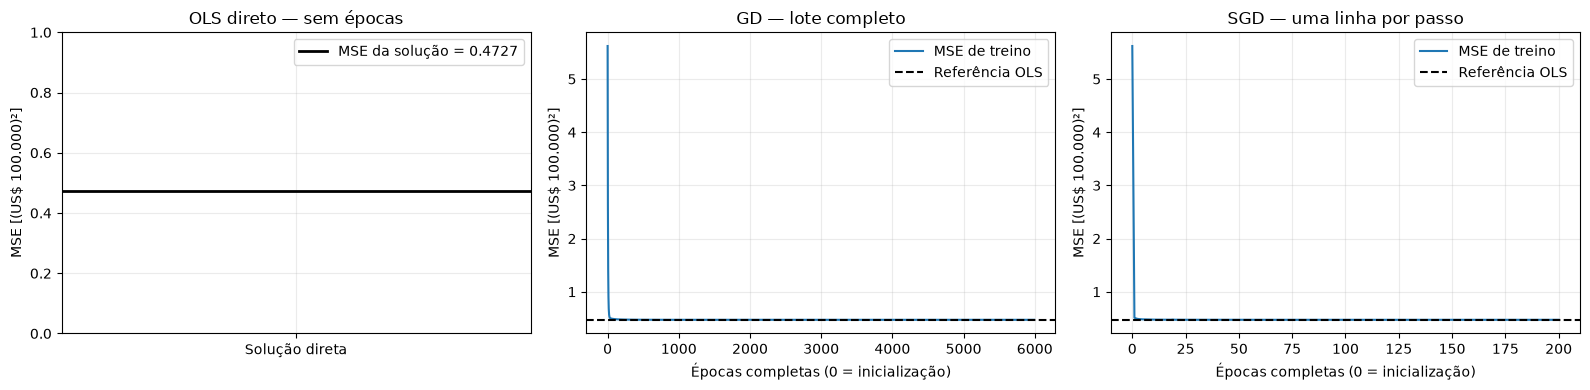

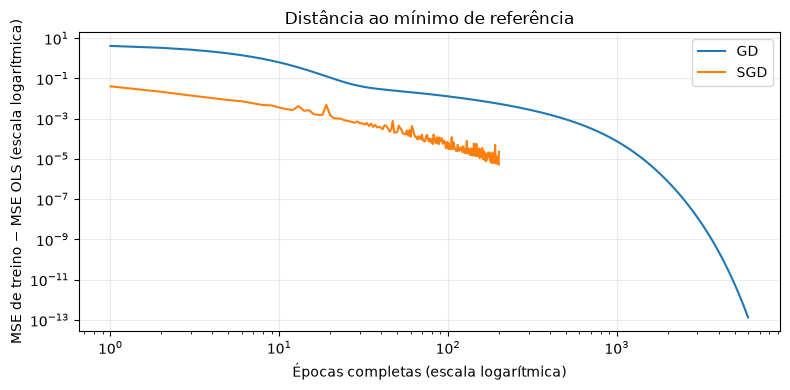

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].axhline(mse_ols, color="black", linewidth=2,
                label=f"MSE da solução = {mse_ols:.4f}")
axes[0].set_xlim(0, 1)
axes[0].set_xticks([0.5], ["Solução direta"])
axes[0].set_title("OLS direto — sem épocas")

for ax, history, title in zip(
    axes[1:], [history_gd, history_sgd], ["GD — lote completo", "SGD — uma linha por passo"]
):
    ax.plot(np.arange(history.size), history, label="MSE de treino")
    ax.axhline(mse_ols, color="black", linestyle="--", label="Referência OLS")
    ax.set_xlabel("Épocas completas (0 = inicialização)")
    ax.set_title(title)

for ax in axes:
    ax.set_ylabel("MSE [(US$ 100.000)²]")
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, history_gd.size), np.maximum(history_gd[1:] - mse_ols, 1e-16), label="GD")
ax.plot(np.arange(1, history_sgd.size), np.maximum(history_sgd[1:] - mse_ols, 1e-16), label="SGD")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Épocas completas (escala logarítmica)")
ax.set_ylabel("MSE de treino − MSE OLS (escala logarítmica)")
ax.set_title("Distância ao mínimo de referência")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


**Explicação dos gráficos e do código**

- `subplots(1, 3)` cria um painel por procedimento. `axhline` desenha o valor constante de OLS.
- `plot` usa a posição do histórico como número de épocas; o índice 0 é o estado antes do treino.
- As linhas tracejadas mostram o mesmo mínimo de referência, calculado apenas no treino.
- O segundo gráfico exibe $J(\theta_e)-J(\widehat\theta_{OLS})$: quanto menor, mais próxima a perda está da solução direta. O zero não cabe em escala logarítmica; `maximum(..., 1e-16)` limita somente o desenho, sem alterar parâmetros ou métricas. Diferenças minúsculas podem ser arredondamento.
- As escalas logarítmicas permitem ver a aproximação final, que fica escondida no gráfico com o grande erro inicial. Uma posição diferente no eixo horizontal ainda não equivale a tempo diferente de execução.

**Como interpretar:** GD com taxa adequada tende a reduzir suavemente a perda quadrática. SGD pode apresentar subidas locais, pois otimiza cada exemplo em sequência. Se a curva de SGD ficar acima de OLS ao final, resta erro de otimização; isso não significa que seu modelo tenha uma capacidade diferente. Nenhuma curva de treino, sozinha, comprova generalização.


## 12. Métricas de regressão e baseline

Usaremos previsões em dólares para avaliar o que os erros significam na escala original. Acurácia e matriz de confusão não são adequadas para comparar valores contínuos.

Para um conjunto de avaliação com $n$ linhas, definimos:

$$\operatorname{MSE}=\frac1n\sum_i(\widehat y_i-y_i)^2,$$
$$\operatorname{RMSE}=\sqrt{\operatorname{MSE}},\qquad
\operatorname{MAE}=\frac1n\sum_i|\widehat y_i-y_i|,$$
$$R^2=1-\frac{\sum_i(y_i-\widehat y_i)^2}{\sum_i(y_i-\overline y_{\mathrm{avaliação}})^2}.$$

- **MSE:** é a perda já deduzida, agora em US$²; menor é melhor.
- **RMSE:** desfaz o quadrado na unidade e volta a dólares. Mantém a sensibilidade aos erros grandes, pois a raiz vem **depois** da média dos quadrados. Não é simplesmente o erro absoluto médio.
- **MAE:** mede o tamanho absoluto médio dos erros, em dólares, com penalização linear. Não é a função usada para treinar estes modelos.
- **$R^2$:** compara a soma de quadrados do modelo com a de uma previsão constante igual à média do **conjunto avaliado**. Vale 1 para ajuste perfeito, 0 quando iguala essa referência e pode ser negativo. Não é uma porcentagem de previsões corretas. Se todas as respostas forem iguais, o denominador será zero e a fórmula não estará definida.

### De onde vem o baseline pela média?

Para um preditor constante $c$, minimize $J(c)=m^{-1}\sum_i(c-y_i)^2$. Derivando e igualando a zero:

$$\frac{dJ}{dc}=\frac2m\sum_i(c-y_i)=2(c-\overline y_{treino})=0
\quad\Longrightarrow\quad c=\overline y_{treino}.$$

A média do treino é, portanto, o melhor preditor constante para MSE naquele treino. Vamos aplicá-la também ao teste, sem aprender a média do teste. Por isso o $R^2$ desse baseline no teste pode ser ligeiramente negativo: o denominador da métrica usa a média de avaliação, enquanto a previsão usa a média do treino.


In [12]:
def regression_metrics(y_real, y_pred):
    erros = y_pred - y_real
    mse = np.mean(erros ** 2)
    sst = np.sum((y_real - y_real.mean()) ** 2)
    r2 = 1.0 - np.sum(erros ** 2) / sst if sst > 0 else np.nan
    return {"MSE (US$²)": mse, "RMSE (US$)": np.sqrt(mse),
            "MAE (US$)": np.mean(np.abs(erros)), "R²": r2}


def predict_numpy(X_b, theta):
    return (X_b @ theta) * UNIDADE_ALVO

parametros_numpy = {"NumPy — OLS direto": theta_ols,
                    "NumPy — GD": theta_gd, "NumPy — SGD": theta_sgd}
predicoes = {"Baseline — média do treino": (
    np.full(y_train.shape, y_train.mean()), np.full(y_test.shape, y_train.mean())
)}
for nome, theta in parametros_numpy.items():
    predicoes[nome] = (predict_numpy(X_train_b, theta), predict_numpy(X_test_b, theta))


def build_comparison(predicoes):
    linhas = []
    for nome, (pred_train, pred_test) in predicoes.items():
        for conjunto, real, previsto in [("Treino", y_train, pred_train),
                                         ("Teste", y_test, pred_test)]:
            linhas.append({"Modelo": nome, "Conjunto": conjunto,
                           **regression_metrics(real, previsto)})
    return pd.DataFrame(linhas).set_index(["Modelo", "Conjunto"])

comparacao_numpy = build_comparison(predicoes)
comparacao_numpy.round(3)


MSE (US$²)  RMSE (US$)  MAE (US$)  \
Modelo                     Conjunto                                        
Baseline — média do treino Treino    1.327857e+10  115232.671  91159.753   
                           Teste     1.346381e+10  116033.677  91532.012   
NumPy — OLS direto         Treino    4.726936e+09   68752.714  49877.571   
                           Teste     4.702171e+09   68572.380  49843.230   
NumPy — GD                 Treino    4.726936e+09   68752.714  49877.570   
                           Teste     4.702171e+09   68572.379  49843.228   
NumPy — SGD                Treino    4.727162e+09   68754.360  49861.091   
                           Teste     4.703274e+09   68580.421  49822.577   

                                        R²  
Modelo                     Conjunto         
Baseline — média do treino Treino    0.000  
                           Teste    -0.000  
NumPy — OLS direto         Treino    0.644  
                           Teste     0.651  
NumPy — GD                 Treino    0.644  
                           Teste     0.651  
NumPy — SGD                Treino    0.644  
                           Teste     0.651

**Leitura do código:** `regression_metrics` calcula as quatro fórmulas diretamente em NumPy, incluindo a proteção para alvo constante. `predict_numpy` converte o produto matricial de volta para dólares. O baseline usa `y_train.mean()` em ambos os conjuntos. O dicionário guarda uma dupla de vetores de previsões por modelo; `build_comparison` monta uma linha por modelo e conjunto. O arredondamento altera apenas a apresentação.

Compare primeiro cada modelo com o baseline. Depois compare treino e teste: uma diferença grande pode indicar dificuldade de generalização, mas uma divisão isolada não identifica sua causa. Não usamos a tabela para refazer o sorteio, escolher uma taxa ou selecionar épocas.


## 13. Depois do NumPy: OLS e SGD com scikit-learn

### 13.1. `LinearRegression`: mesmo critério de mínimos quadrados

`LinearRegression` ajusta mínimos quadrados sem penalização. Para entradas densas, usa um solucionador numérico de mínimos quadrados. Não executa o nosso laço de GD. Receberá as mesmas 12 entradas padronizadas e o mesmo alvo na unidade de US$ 100.000. Seu intercepto é aprendido automaticamente, então **não passamos a coluna de 1s**.

### 13.2. `SGDRegressor`: mesmo minimizador, convenção de escala diferente

Configuramos `loss="squared_error"`, `penalty=None` e `average=False`. Desse modo não há regularização nem média de pesos. A perda quadrática usada nas atualizações da biblioteca segue a convenção $\ell_i=\tfrac12(\widehat y'_i-y'_i)^2$, com gradiente $\tilde x_i^T(\widehat y'_i-y'_i)$. O nosso gradiente individual tem um fator 2. O minimizador não muda, mas a mesma taxa numérica não produziria o mesmo tamanho de passo.

Para a referência da biblioteca usaremos `learning_rate="invscaling"`:

$$\eta_t=\frac{\eta_0}{t^{\mathrm{power\_t}}}.$$

Aqui $t$ é o contador interno de atualizações, começando positivo; `power_t=0.25` controla a velocidade do decréscimo. Esse cronograma difere do nosso decréscimo por época. Portanto, não esperamos coeficientes idênticos em um número finito de épocas.

Usaremos `partial_fit` uma vez por época. Esse método executa uma época de SGD e preserva os pesos para a próxima chamada. Assim conseguimos medir o **MSE externo de todo o treino** após cada época, na mesma definição dos gráficos manuais. `tol=None` explicita o orçamento fixo, `shuffle=True` embaralha as amostras e `random_state=42` torna a execução reproduzível no ambiente usado.


In [13]:
model_ols = LinearRegression()
model_ols.fit(X_train_scaled, y_train_u)

model_sgd = SGDRegressor(
    loss="squared_error", penalty=None, fit_intercept=True,
    learning_rate="invscaling", eta0=0.0002, power_t=0.25,
    shuffle=True, random_state=42, tol=None, average=False
)
history_sklearn_sgd = [np.mean(y_train_u ** 2)]
for _ in range(200):
    model_sgd.partial_fit(X_train_scaled, y_train_u)
    pred_u = model_sgd.predict(X_train_scaled)
    history_sklearn_sgd.append(np.mean((pred_u - y_train_u) ** 2))
history_sklearn_sgd = np.array(history_sklearn_sgd)

for nome, modelo in [("sklearn — OLS direto", model_ols), ("sklearn — SGD", model_sgd)]:
    predicoes[nome] = (modelo.predict(X_train_scaled) * UNIDADE_ALVO,
                      modelo.predict(X_test_scaled) * UNIDADE_ALVO)

comparacao = build_comparison(predicoes)
comparacao.round(3)


MSE (US$²)  RMSE (US$)  MAE (US$)  \
Modelo                     Conjunto                                        
Baseline — média do treino Treino    1.327857e+10  115232.671  91159.753   
                           Teste     1.346381e+10  116033.677  91532.012   
NumPy — OLS direto         Treino    4.726936e+09   68752.714  49877.571   
                           Teste     4.702171e+09   68572.380  49843.230   
NumPy — GD                 Treino    4.726936e+09   68752.714  49877.570   
                           Teste     4.702171e+09   68572.379  49843.228   
NumPy — SGD                Treino    4.727162e+09   68754.360  49861.091   
                           Teste     4.703274e+09   68580.421  49822.577   
sklearn — OLS direto       Treino    4.726936e+09   68752.714  49877.571   
                           Teste     4.702171e+09   68572.380  49843.230   
sklearn — SGD              Treino    4.779607e+09   69134.702  50031.975   
                           Teste     4.756064e+09   68964.220  49937.880   

                                        R²  
Modelo                     Conjunto         
Baseline — média do treino Treino    0.000  
                           Teste    -0.000  
NumPy — OLS direto         Treino    0.644  
                           Teste     0.651  
NumPy — GD                 Treino    0.644  
                           Teste     0.651  
NumPy — SGD                Treino    0.644  
                           Teste     0.651  
sklearn — OLS direto       Treino    0.644  
                           Teste     0.651  
sklearn — SGD              Treino    0.640  
                           Teste     0.647

**Explicação linha a linha**

1. Criamos e ajustamos o modelo direto com `fit`, usando os mesmos dados preparados anteriormente.
2. Configuramos SGD conforme a perda e o cronograma descritos acima.
3. Antes do primeiro `partial_fit`, registramos o MSE correspondente a pesos e intercepto zero, para que o índice 0 tenha o mesmo significado do histórico manual.
4. Cada chamada a `partial_fit` continua o ajuste anterior por uma época. Chamar `fit` repetidamente sem preservar estado reiniciaria o modelo e não teria esse significado.
5. Calculamos a perda de treino a partir das previsões externas da biblioteca; ela é MSE completo, mesmo que a atualização interna use metade do quadrado.
6. Convertemos previsões de ambos os conjuntos para dólares e acrescentamos os dois modelos à tabela.

`SGDRegressor` não fornece uma opção para reproduzir exatamente nosso GD em lote completo. Por isso a comparação inclui GD manual contra a solução direta do mesmo objetivo, e inclui SGD manual contra SGD da biblioteca. Não chamamos um treino estocástico de GD em lote.


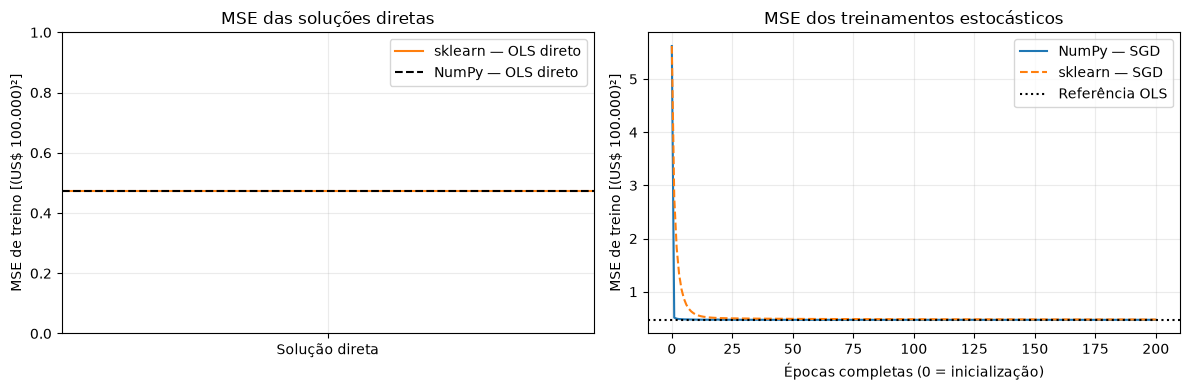

Maior diferença de previsões OLS no teste (US$): 5.238689482212067e-10
Diferença entre MSE de treino GD e OLS (unidade²): 1.3200551762793111e-13
Diferença entre MSE de treino SGD e OLS (unidade²): 2.262425107396604e-05


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].axhline(np.mean((model_ols.predict(X_train_scaled) - y_train_u) ** 2),
                color="tab:orange", label="sklearn — OLS direto")
axes[0].axhline(mse_ols, color="black", linestyle="--", label="NumPy — OLS direto")
axes[0].set_xticks([0.5], ["Solução direta"])
axes[0].set_xlim(0, 1)
axes[0].set_title("MSE das soluções diretas")
axes[1].plot(history_sgd, label="NumPy — SGD")
axes[1].plot(history_sklearn_sgd, linestyle="--", label="sklearn — SGD")
axes[1].axhline(mse_ols, color="black", linestyle=":", label="Referência OLS")
axes[1].set_xlabel("Épocas completas (0 = inicialização)")
axes[1].set_title("MSE dos treinamentos estocásticos")
for ax in axes:
    ax.set_ylabel("MSE de treino [(US$ 100.000)²]")
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

p_numpy_ols = predicoes["NumPy — OLS direto"][1]
p_sklearn_ols = predicoes["sklearn — OLS direto"][1]
print("Maior diferença de previsões OLS no teste (US$):",
      np.max(np.abs(p_numpy_ols - p_sklearn_ols)))
print("Diferença entre MSE de treino GD e OLS (unidade²):", history_gd[-1] - mse_ols)
print("Diferença entre MSE de treino SGD e OLS (unidade²):", history_sgd[-1] - mse_ols)


### Leitura dos resultados desta execução

Com a semente e as configurações acima, a solução direta teve MSE de treino de aproximadamente **0,472694 (US$ 100.000)²**. GD terminou após **5.989 atualizações**, com norma do gradiente abaixo de $10^{-7}$ e diferença de MSE para OLS de cerca de $1,32 \times 10^{-13}$. Assim, nesta execução a diferença de otimização de GD é desprezível na escala das métricas apresentadas.

SGD manual realizou **3.302.400 atualizações individuais em 200 épocas** e terminou com MSE de treino de aproximadamente **0,472716**. A diferença para OLS foi cerca de $2,26 \times 10^{-5}$: a perda ficou próxima do mínimo, mas o gradiente completo ainda teve norma aproximadamente 0,0166. Não podemos afirmar que ele cumpriu a tolerância usada em GD. O gráfico logarítmico permite enxergar tanto essa aproximação quanto as oscilações que ficam escondidas no gráfico geral.

No teste, o RMSE foi aproximadamente **US$ 68.572** para OLS e GD, **US$ 68.580** para SGD manual e **US$ 68.964** para SGD da biblioteca. O baseline pela média teve RMSE de aproximadamente **US$ 116.034**. OLS atingiu $R^2$ de aproximadamente **0,651**. Esses valores descrevem esta divisão; diferenças pequenas não estabelecem superioridade geral entre os procedimentos.

As previsões diretas de NumPy e scikit-learn diferiram no máximo cerca de $5,24 \times 10^{-10}$ dólares no teste, compatível com arredondamento numérico. O SGD da biblioteca ainda apresentou perda de treino maior após seu orçamento de épocas; seus passos menores ao longo do tempo e seu cronograma distinto ajudam a interpretar essa aproximação. Comparar as curvas não isola o efeito de uma biblioteca, pois as trajetórias não usam configurações equivalentes.

As linhas do painel de OLS devem quase coincidir: elas resolvem o mesmo problema, com diferenças de arredondamento e de convenções numéricas de posto. Os dois SGD usam o mesmo conjunto de funções, mas cronogramas de taxa e detalhes de embaralhamento distintos. Sua diferença final pode decorrer de otimização incompleta.

O segundo painel compara MSE por época, sem avaliar tempo de processamento. As diferenças para o mínimo são calculadas no **treino**. Se uma diferença for negativa só na ordem da precisão de ponto flutuante, ela não evidencia uma solução matematicamente melhor que o mínimo.


## 14. Diagnóstico: previsões e resíduos no teste

Agora olharemos o teste para descrever o modelo direto, sem usá-lo para reajustar configurações. No treinamento definimos erro como previsão menos observado; para o diagnóstico usaremos a convenção usual de **resíduo observado menos previsto**:

$$r_i=y_i-\widehat y_i=-e_i.$$

O sinal muda, mas MSE, RMSE e MAE permanecem iguais. Resíduo positivo indica subestimação e negativo indica superestimação. O gráfico real × previsto deve se aproximar da diagonal $\widehat y=y$. No gráfico de resíduos, procuramos curvaturas e mudanças de dispersão: elas sugerem relações não capturadas ou variância dos erros não constante (**heterocedasticidade**). Um gráfico sozinho não demonstra independência, normalidade ou causalidade.


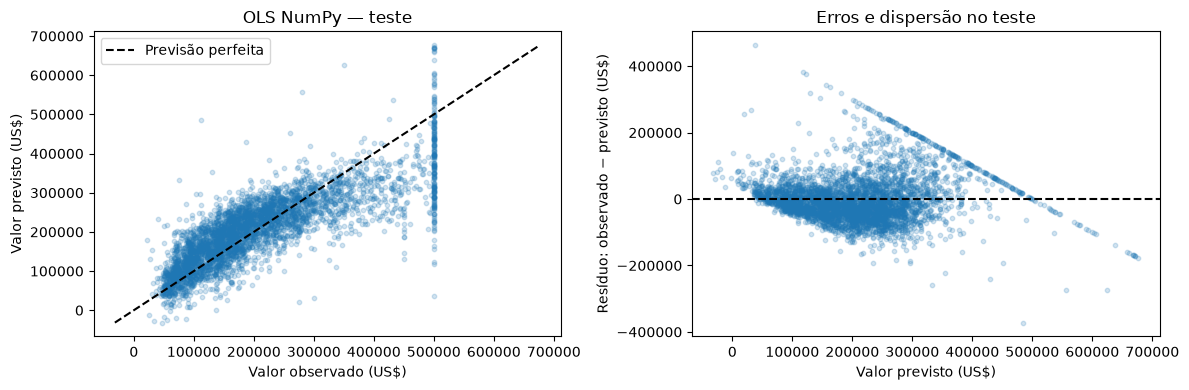

Previsões negativas no teste: 8
Previsões acima do máximo observado no treino: 33


In [15]:
residuos_teste = y_test - p_numpy_ols
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_test, p_numpy_ols, s=10, alpha=0.2)
limites = [min(y_test.min(), p_numpy_ols.min()), max(y_test.max(), p_numpy_ols.max())]
axes[0].plot(limites, limites, "k--", label="Previsão perfeita")
axes[0].set_xlabel("Valor observado (US$)")
axes[0].set_ylabel("Valor previsto (US$)")
axes[0].set_title("OLS NumPy — teste")
axes[0].legend()
axes[1].scatter(p_numpy_ols, residuos_teste, s=10, alpha=0.2)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_xlabel("Valor previsto (US$)")
axes[1].set_ylabel("Resíduo: observado − previsto (US$)")
axes[1].set_title("Erros e dispersão no teste")
plt.tight_layout()
plt.show()

print("Previsões negativas no teste:", np.sum(p_numpy_ols < 0))
print("Previsões acima do máximo observado no treino:",
      np.sum(p_numpy_ols > y_train.max()))


`scatter` desenha uma observação por ponto; `alpha` reduz a opacidade para revelar sobreposições. A diagonal é uma referência geométrica, não uma reta ajustada aos dados do teste. O segundo painel coloca resíduos contra previsões e usa uma linha horizontal em zero.

A concentração de valores no limite superior do alvo pode aparecer como uma faixa no primeiro painel e uma estrutura inclinada no segundo. Previsões negativas e extrapolações acima do máximo evidenciam que o modelo não impõe limites à saída. Mantemos esses resultados no cálculo das métricas, sem corrigi-los após observar o teste.


## 15. Interpretar coeficientes na escala original

Os parâmetros foram aprendidos com $x'_j=(x_j-\mu_j)/s_j$ e $y'=y/U$, onde $U=100000$. Substituindo essas expressões na previsão:

$$\widehat y=U\left[b+\sum_j w_j\frac{x_j-\mu_j}{s_j}\right]
=\underbrace{U\left[b-\sum_j\frac{w_j\mu_j}{s_j}\right]}_{b_{original}}
+\sum_j\underbrace{\frac{Uw_j}{s_j}}_{\beta_j}x_j.$$

Logo, $\beta_j=Uw_j/s_j$ e $b_{original}=Ub-\sum_j\beta_j\mu_j$.

Para entradas numéricas, $\beta_j$ representa a mudança prevista em dólares por uma unidade adicional dessa entrada, mantendo as outras fixas. Para indicadores, representa a diferença em dólares para a categoria de referência, com as outras entradas fixas. O intercepto original corresponde a todas as entradas numéricas zero e à categoria de referência, uma situação que pode estar fora da realidade desta base.

Os pesos padronizados multiplicados por $U$ representam uma mudança de um desvio padrão do treino. Porém, em indicadores, essa mudança não equivale à troca completa de categoria; para isso, olhamos os coeficientes na escala original.


In [16]:
betas_originais = UNIDADE_ALVO * theta_ols[1:] / std
intercepto_original = UNIDADE_ALVO * theta_ols[0] - betas_originais @ mean
coeficientes = pd.DataFrame({
    "Entrada": nomes_entradas,
    "Peso por 1 desvio de treino (US$)": UNIDADE_ALVO * theta_ols[1:],
    "Coeficiente na escala original (US$ por unidade)": betas_originais
})
print("Intercepto original (US$):", intercepto_original)
print("Referência das categorias:", referencia)
coeficientes


Intercepto original (US$): -2268386.254822606
Referência das categorias: <1H OCEAN


,Entrada,Peso por 1 desvio de treino (US$),Coeficiente na escala original (US$ por unidade)
0,longitude,-53608.596317,-26779.094554
1,latitude,-54035.671691,-25378.877340
2,housing_median_age,13309.228422,1055.780692
3,total_rooms,-11237.193541,-5.162461
4,total_bedrooms,30939.270685,74.161492
5,population,-42586.529676,-37.369730
6,households,27650.803924,72.569286
7,median_income,73873.226912,38847.654032
8,ocean=INLAND,-18150.638678,-39040.526175
9,ocean=ISLAND,2722.288986,156464.143892


O código traduz diretamente a substituição algébrica. `std` e `mean` incluem tanto colunas numéricas quanto indicadores; os pesos preservam a mesma ordem de `nomes_entradas`.

Um sinal inesperado não prova erro: entradas como cômodos, dormitórios e domicílios são correlacionadas, e cada coeficiente é uma associação **condicional às demais entradas**. Correlação entre colunas pode tornar pesos sensíveis a pequenas mudanças na amostra. Não interpretamos pesos como efeitos causais nem como garantia de comportamento fora da distribuição observada.


## 16. Verificações de consistência

Vamos conferir separação sem sobreposição, ausência de números inválidos, alinhamento do histórico com os parâmetros retornados, equivalência da conversão de coeficientes e acordo das nossas métricas com o scikit-learn. São verificações numéricas do exercício; não comprovam generalização.


In [17]:
assert np.intersect1d(train_indices, test_indices).size == 0
assert train_indices.size + test_indices.size == y.size
assert np.isfinite(X_train_b).all() and np.isfinite(X_test_b).all()
assert np.isclose(history_gd[-1], mse_loss(theta_gd, X_train_b, y_train_u))
assert np.isclose(history_sgd[-1], mse_loss(theta_sgd, X_train_b, y_train_u))
assert np.isclose(history_sklearn_sgd[-1],
                  np.mean((model_sgd.predict(X_train_scaled) - y_train_u) ** 2))
assert np.allclose(intercepto_original + X_test @ betas_originais, p_numpy_ols)
assert np.allclose(p_numpy_ols, p_sklearn_ols, rtol=1e-7, atol=1e-4)
for nome, (_, pred_test) in predicoes.items():
    metricas = regression_metrics(y_test, pred_test)
    assert np.isfinite(pred_test).all(), nome
    assert np.isclose(metricas["MSE (US$²)"], mean_squared_error(y_test, pred_test)), nome
    assert np.isclose(metricas["MAE (US$)"], mean_absolute_error(y_test, pred_test)), nome
    assert np.isclose(metricas["R²"], r2_score(y_test, pred_test)), nome
print("Verificações concluídas: dados, históricos, coeficientes e métricas consistentes.")


Verificações concluídas: dados, históricos, coeficientes e métricas consistentes.


## 17. Relação entre fórmulas, algoritmos e código

| Conceito | Fórmula ou implementação |
|---|---|
| Previsão contínua | `X_b @ theta`, depois converter para dólares |
| MSE | `np.mean((X_b @ theta - y) ** 2)` |
| Condição de OLS | $X_b^TX_b\widehat\theta=X_b^Ty$ |
| Solução direta estável | `np.linalg.lstsq(X_b, y, rcond=None)` |
| Gradiente completo | `2 * X_b.T @ (X_b @ theta - y) / y.size` |
| Atualização GD | `theta -= alpha * grad` |
| Gradiente individual | `2 * X_b[i] * (X_b[i] @ theta - y[i])` |
| Atualização SGD | `theta -= eta * grad_i` |
| Uma época GD | Uma atualização usando todas as amostras |
| Uma época SGD | Uma atualização por amostra, após embaralhar |
| Referência direta sklearn | `LinearRegression().fit(...)` |
| Referência estocástica sklearn | `SGDRegressor(penalty=None).partial_fit(...)` |

**Perguntas de interpretação**

1. **OLS, GD e SGD são três modelos diferentes?** Aqui usam a mesma família linear e o mesmo critério de mínimos quadrados. OLS nomeia o critério; solução direta, GD e SGD são maneiras de obter ou aproximar seu mínimo.
2. **Por que o gradiente de GD divide por $m$, mas o de SGD não?** GD calcula a média explícita das derivadas; a amostragem uniforme motiva o uso de uma derivada individual como estimativa dessa média.
3. **Por que SGD pode aumentar o MSE de uma época para outra?** Cada atualização favorece um exemplo, não necessariamente o erro médio de todos os exemplos.
4. **Por que OLS direto não tem curva de treinamento?** O método resolve o sistema de mínimos quadrados sem uma trajetória de épocas exposta. A linha constante identifica a perda da solução.
5. **Uma perda de treino menor sempre melhora o teste?** Não. Aproximar melhor o mínimo resolve a otimização do treino; generalização é outra propriedade.
6. **MSE de 0,5 significa erro de cinquenta centavos?** Não. O gráfico usa unidades de (US$ 100.000)². Esse MSE corresponde a RMSE $\sqrt{0,5}\times100000$, aproximadamente US$ 70.711.
7. **Por que remover um indicador?** Com intercepto, todos os indicadores somariam a coluna de 1s. A referência remove essa dependência exata e permite interpretar diferenças de categorias.

**Limites desta aula:** uma única divisão aleatória, relações lineares aditivas, possível teto no alvo, categorias raras e correlação espacial. Não implementamos regularização, polinômios, intervalos de previsão ou validação cruzada. Investigar essas técnicas exige explicar seus objetivos e separar validação de teste antes de escolher configurações. Os resultados descrevem esta base histórica, não preços atuais.

### Referências

- [Descrição da versão modificada de California Housing](https://github.com/ageron/handson-ml/blob/master/datasets/housing/README.md): unidade de observação, origem histórica e modificações do arquivo.
- [NumPy — `linalg.lstsq`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html): solução numérica de mínimos quadrados.
- [scikit-learn — mínimos quadrados ordinários](https://scikit-learn.org/stable/modules/linear_model.html#ordinary-least-squares).
- [scikit-learn — `LinearRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html).
- [scikit-learn — `SGDRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDRegressor.html) e [detalhes da perda e da atualização estocástica](https://scikit-learn.org/stable/modules/sgd.html#mathematical-formulation).
- [scikit-learn — métricas de regressão](https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics).
